# embeddingsModel

In [1]:
#Loading required packages
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torchvision.utils as vutils
import torchvision.datasets as datasets
from torchvision.transforms import transforms as transform
import matplotlib.animation as animation
from matplotlib import pyplot as plt
from skimage import io
from tqdm import tqdm
import numpy as np
import cv2



In [2]:
#Conncect Google Drive
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
#setting device,i.e GPU or CPU
if torch.cuda.is_available():
    device = torch.device("cuda:0")
    print("Running on GPU ->",device)
else:
    device = torch.device("cpu")
    print("Running on CPU ->",device)

Running on GPU -> cuda:0


In [ ]:
!unzip /content/CelebAMask-HQ-attribute-anno.zip

unzip:  cannot find or open /content/CelebAMask-HQ-attribute-anno.zip, /content/CelebAMask-HQ-attribute-anno.zip.zip or /content/CelebAMask-HQ-attribute-anno.zip.ZIP.


In [ ]:
import pandas as pd
df = pd.read_csv('/content/CelebAMask-HQ-attribute-anno (2).txt', sep=" ")
df


# convert label to text and TEXT to Embeddings

In [ ]:
import os
import pandas as pd
from random import randint, choice, shuffle, sample

ALL_ATTRIBUTE =  False
NUM_CAPTION = 10 if ALL_ATTRIBUTE is False else 1

# Create a dictionary with attributes and their values
ATTRIBUTES = {
    'IsAttributes': ['Attractive', 'Bald', 'Chubby', 'Young', 'Smiling'],
    'HasAttributes': ['Eyeglasses', 'Arched_Eyebrows', 'Bags_Under_Eyes', 'Bangs', 'Big_Lips', 'Big_Nose', 'Black_Hair',
               'Blond_Hair', 'Brown_Hair', 'Bushy_Eyebrows', 'Double_Chin', 'Goatee', 'Gray_Hair', 'Straight_Hair',
               'Sideburns', 'Rosy_Cheeks', 'Receding_Hairline', 'Pointy_Nose', 'Pale_Skin', 'Oval_Face', 'Narrow_Eyes',
               'Mustache', 'Mouth_Slightly_Open', 'High_Cheekbones', 'Wavy_Hair'],
    'WearAttributes': ['Wearing_Necktie', 'Wearing_Necklace', 'Wearing_Lipstick', 'Wearing_Hat', 'Wearing_Earrings',
                'Heavy_Makeup'],
}

gender = {
    'female': ['She', 'This woman', 'The woman', 'The person', 'This person'], # in the picture, in the image, the entire face of
    'male': ['He', 'This man', 'The man', 'The person', 'This person']
}

IsVerb = [' is ', ' looks ', ' appears to be ']
WearVerb =[' wears ', ' is wearing ']
HaveVerb = [' has ', ' is with ']

def get_subject(img_attribute):
    '''
    This function gives options of subject for a given image.
    '''
    if img_attribute['Male'] == str(-1):
        return gender['female']
    else:
        return gender['male']

def get_feature(img_attribute):
    '''
    This function gives three categories attributes for a given image. The output for image 29999.jpg is shown below.
    feature = {'IsAttributes': ['Attractive', 'Smiling'],
    'HasAttributes': ['Bangs', 'Brown_Hair', 'Rosy_Cheeks', 'Mouth_Slightly_Open', 'High_Cheekbones', 'Wavy_Hair'],
    'WearAttributes': ['Wearing_Lipstick', 'Wearing_Earrings', 'Heavy_Makeup']}
    '''
    feature = {}
    for attribute, values in ATTRIBUTES.items():
        feature[attribute] = [value for value in values if img_attribute[value] == str(1)]
    return feature

def get_caption(img_attribute, num_caption):
    '''
    This function gives a certain numbers of captions for every images in the dataset.
    '''
    subject = get_subject(img_attribute)
    feature = get_feature(img_attribute)

    captions = []

    # randomly select number of captions to generate
    for _ in range(num_caption):

        if ALL_ATTRIBUTE:
            IsAttributes = ', '.join(feature['IsAttributes']).lower()[::]
            HasAttributes = ', '.join(feature['HasAttributes']).replace('_', ' ').lower()[::]
            WearAttributes = ', '.join(feature['WearAttributes']).replace('Wearing_', '').replace('_', ' ').lower()[::]

            caption = f'The person in the picture is {IsAttributes}. {choice(subject)}{choice(HaveVerb)}{HasAttributes}. {choice(subject)}{choice(WearVerb)}{WearAttributes}.'
            captions.append(caption)

        else:
            # get number of attributes in each category
            len_i = len(feature['IsAttributes'])
            len_h = len(feature['HasAttributes'])
            len_w = len(feature['WearAttributes'])

            # randomly select number of attributes to use for each category
            c_i = randint(1, len_i)  if len_i > 1 else len_i
            c_h = randint(1, len_h)  if len_h > 1 else len_h
            c_w = randint(1, len_w)  if len_w > 1 else len_w

            # randomly select attributes from each category (should suffle the list first)
            # cannot handle the case where original/sampled attribute list is empty
            IsAttributes = ', '.join(sample(feature['IsAttributes'], c_i)).lower()[::]
            HasAttributes = ', '.join(sample(feature['HasAttributes'], c_h)).replace('_', ' ').lower()[::]
            WearAttributes = ', '.join(sample(feature['WearAttributes'], c_w)).replace('Wearing_', '').replace('_', ' ').lower()[::]

            # randomly select verbs for each category
            SelectWearAttributes = f'{choice(WearVerb)}{WearAttributes}'
            SelectHasAttributes = f'{choice(HaveVerb)}{HasAttributes}'
            SelectIsAttributes = f'{choice(subject)}{choice(IsVerb)}{IsAttributes}'

            # define caption formats here
            caption_format = {
                '1': f'{SelectIsAttributes}. {choice(subject)}{SelectHasAttributes} and{SelectWearAttributes}.',
                '2': f'{SelectIsAttributes} and{SelectHasAttributes}. {choice(subject)}{SelectWearAttributes}.',
                '3': f'This is a {IsAttributes} person. {choice(subject)}{SelectHasAttributes}. {choice(subject)}{SelectWearAttributes}.',
            }

            # randomly select one of the caption format
            random_format = choice(list(caption_format.keys()))
            caption = caption_format[random_format]
            captions.append(caption)

    return captions



anno_path = '/content/CelebAMask-HQ-attribute-anno (2).txt'
save_path = 'celeba_caption'

if not os.path.exists(save_path):
    os.makedirs(save_path)

with open(anno_path, 'r') as f:
    lines = f.readlines()
    print(len(lines))
    num_images = len(lines)
    attributes = lines[0].split()
    print((attributes))
    # Store the attributes for each image in a dictionary
    image_attributes = {}
    for i in range(1,num_images):
        print(lines[i].split())
        image_id, *attr_values = lines[i].split()
        image_attributes[image_id] = dict(zip(attributes, attr_values))

for num in range (0, num_images):
    captions = get_caption(image_attributes['{}.jpg'.format(num)], NUM_CAPTION)

    with open('{}/{}.txt'.format(save_path, str(num)), "w") as f:
        f.write("\n".join(captions))

print ('all done!')


In [ ]:
# code to preprocess image and text data

from google.colab import drive
drive.mount('/content/drive')

text_loc = '/content/celeba_caption'
img_loc = '/content/content/dataCelebA/CelebA-HQ-img'


os.chdir(text_loc)
print(os.getcwd)
text_map ={}
files = os.listdir()
os.chdir(text_loc)
print(os.getcwd)
text_map ={}
files = os.listdir()
for i in tqdm(range(len(files))):
    path = os.path.join(text_loc,files[i])
    f = open(path,'r')
    text = [int(files[i].split('.')[0])]
    for line in f.readlines():
        text.append(line)
    f.close()
    text_map[int(files[i].split('.')[0])]=text

l = list(text_map.keys())
l.sort()

import json
final_text = []
for i in l:
    final_text.append(text_map[i])


import csv
with open('/content/Project_face_data/text.csv', 'w', encoding='UTF8') as f:
    writer = csv.writer(f)
    for row in final_text:
        writer.writerow(row)


os.chdir(img_loc)
img_files = os.listdir()
img_map = {}
for i in img_files:
    img_map[int(i.split('.')[0])] = i

all_img = list(img_map.keys())
all_img.sort()
all_img_path = []
for img_file in all_img:
    file_name = img_map[img_file]
    all_img_path.append(os.path.join(img_loc,file_name))

data = []
for i in tqdm(range(len(all_img_path))):
    path = all_img_path[i]
    img =io.imread(path)
    img = cv2.resize(img, (64,64),interpolation=cv2.INTER_NEAREST)
    data.append(img)

np.save('/content/Project_face_data/celeb_color64_data.npy',np.array(data))


In [ ]:
data = np.load("/content/drive/MyDrive/AFace /Project_face_data/celeb_color64_data.npy",allow_pickle=True)

In [ ]:
trf = transform.Compose([transform.ToTensor()])
ndata = []
for img in data:
    ndata.append(trf(np.array(img)).numpy())

In [ ]:
data =np.array(ndata)
data = torch.from_numpy(data)
print(data.shape)
tdata = data
print(tdata.shape)
tdata = tdata[:29952]
print(tdata.shape)

In [ ]:
plt.figure(figsize=(12,12))
plt.axis("off")
plt.title("Training Images")
print(tdata.shape)
plt.imshow(np.transpose(vutils.make_grid(tdata[:64], padding=2).cpu(),(1,2,0)))

In [ ]:
import csv
from sent2vec.vectorizer import Vectorizer
file = open("/content/drive/MyDrive/AFace /Project_face_data/text.csv")
csvreader = csv.reader(file)
all_text = []
for row in csvreader:
    all_text.append(row)
file.close()
for x in all_text[0]:
    print(x)

In [ ]:
import re
def clean_text(text):
    text = text.lower()
    text = re.sub(r"i'm","i am", text)
    text = re.sub(r"he's","he is", text)
    text = re.sub(r"she's","she is", text)
    text = re.sub(r"that's","that is", text)
    text = re.sub(r"what's","what is", text)
    text = re.sub(r"where's","where is", text)
    text = re.sub(r"it's","it is",text)
    text = re.sub(r"don't","do not",text)
    text = re.sub(r"\'ll","will", text)
    text = re.sub(r"\'ve","have", text)
    text = re.sub(r"\'re","are", text)
    text = re.sub(r"\'d","would", text)
    text = re.sub(r"won't","will not", text)
    text = re.sub(r"can't","cannot", text)
    text = re.sub(r"[-()\"#/@;:<>+-=~|.,?]", "", text)
    return text

#clean_text
for i in tqdm(range(len(all_text))):
    all_text[i][1] = clean_text(all_text[i][1])[:-1]

In [ ]:
all_text[0]

In [ ]:
text = []
for i in range(len(all_text)):
    text.append(all_text[i][1])

print("Training texts ->")
text[:16]

In [ ]:
text_vector = []
for i in tqdm(range(0,29952,1024)):
    text_vector.append(sent2vect(text[i:i+1024]))


text_embed = []
for i in range(1,len(text_vector)):
    if i==1:
        res = np.vstack((text_vector[0],text_vector[1]))
    else:
        res = np.vstack((res,text_vector[i]))
    print(res.shape)
text_embed = res[0:29952]

np.save('text_vector2.npy',np.array(text_embed))


In [ ]:
from sent2vec.vectorizer import Vectorizer
def sent2vect(sentence):
    vectorizer = Vectorizer()
    vectorizer.run(sentence)
    vectors = vectorizer.vectors
    return vectors
v = sent2vect(["sentence and","sentence and"])

In [ ]:
images_text = dict()
images_text['images'] = []
images_text['features'] = []
with open('/content/drive/MyDrive/AFace/Project_face_data/text.csv','r') as f:
  l = f.readlines()
  for i in l:
    # print(i)
    sp = i.index(',')
    # print(sp)
    images_text['images'].append((i[:sp]))
    images_text['features'].append(i[sp+2:-2])
    # print(features)
    # break
text_vector = []
for i in tqdm(range(0,29952,1024)):
    text_vector += sent2vect(images_text['features'][i:i+1024])


In [ ]:
print(len(images_text['images']))
print(len(images_text['features']))
print(len(text_vector))

In [ ]:
text_embed = []
for i in range(1,len(text_vector)):
    if i==1:
        res = np.vstack((text_vector[0],text_vector[1]))
    else:
        res = np.vstack((res,text_vector[i]))
    print(res.shape)
text_embed = res

np.save('text_vector2.npy',np.array(text_embed))

In [ ]:
text_embed.shape

In [ ]:
import pandas as pd
df = pd.DataFrame(images_text,index=[i for i in range(0,30000)])

# DataSet Class

In [4]:
import torch
from torch.utils.data import Dataset
from torchvision import transforms
from PIL import Image
import numpy as np

class CustomDataset(Dataset):
    def __init__(self, text, image_file, transform=None):
        self.em_text = text
        self.image_files = image_file
        self.transform = transforms.Compose([transforms.Resize(64), transforms.ToTensor(),transforms.Normalize(0.5,0.5,0.5)])


    def __len__(self):
        return len(self.em_text)

    def __getitem__(self, index):
        encoded_text = self.em_text[index]
        encoded_text = torch.tensor(encoded_text)
        # Load the image
        image = self.image_files[(index+1)%len(self.em_text)]
        image = Image.fromarray(image)

        # Apply transformations to the image
        if self.transform is not None:
            image = self.transform(image)

        return image, encoded_text


In [6]:
all_images = np.load('/content/drive/MyDrive/AFace/Project_face_data/celeb_color64_data.npy')
emtext = np.load('/content/drive/MyDrive/embeddings.npy')

In [7]:
dataset = CustomDataset(emtext, all_images)

In [8]:
Rimg,Rlab = dataset[0]

In [9]:
# Library Import
from __future__ import print_function
import argparse
import os
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.nn.parallel
import torch.backends.cudnn as cudnn
import torch.optim as optim
import torch.utils.data
import torchvision.datasets as dset
import torchvision.transforms as transforms
import torchvision.utils as vutils
from torch.nn import utils
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML
from PIL import Image
import pandas as pd
from PIL import Image

torch.Size([1, 3, 64, 64])


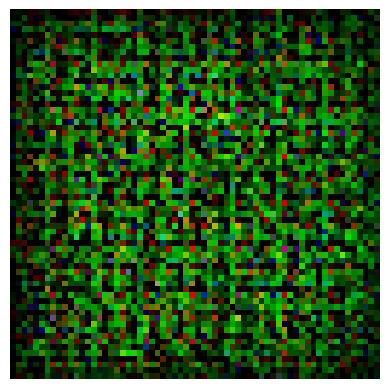

In [10]:
import matplotlib.pyplot as plt
import torch.nn.functional as F
import torch.nn.utils.spectral_norm as spectral_norm

class ConditioningAugmentationD(nn.Module):
  def __init__(self):
    super(ConditioningAugmentationD, self).__init__()

  def forward(self, x):
    mean, log_sigma = torch.split(x, 420, dim=1)  # Split on dim 1 after 384 elements (half)
    stddev = torch.exp(log_sigma)
    epsilon = torch.empty_like(stddev).normal_()  # Generate noise with same shape
    c = mean + stddev * epsilon
    return c

class SelfAttention(nn.Module):
    def __init__(self, in_dim):
        super(SelfAttention, self).__init__()
        self.query_conv = nn.Conv2d(in_dim, in_dim // 8, kernel_size=1)
        self.key_conv = nn.Conv2d(in_dim, in_dim // 8, kernel_size=1)
        self.value_conv = nn.Conv2d(in_dim, in_dim, kernel_size=1)
        self.gamma = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        B, C, H, W = x.size()
        query = self.query_conv(x).view(B, -1, H * W).permute(0, 2, 1)
        key = self.key_conv(x).view(B, -1, H * W)
        attention = F.softmax(torch.bmm(query, key), dim=-1)
        value = self.value_conv(x).view(B, -1, H * W)
        out = torch.bmm(value, attention.permute(0, 2, 1)).view(B, C, H, W)
        out = self.gamma * out + x
        return out

class UpSamplingBlock(nn.Module):
  def __init__(self, in_channels, out_channels):
    super(UpSamplingBlock, self).__init__()
    # self.upsample = nn.Upsample(scale_factor=2)
    # self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False)
    self.conv = nn.ConvTranspose2d(in_channels, out_channels, 4, 2, 1)
    self.norm = nn.BatchNorm2d(out_channels)
    self.relu = nn.ReLU(inplace=True)


  def forward(self, x):
    # x = self.upsample(x)

    x = self.conv(x)
    x = self.norm(x)
    x = self.relu(x)
    return x




class Generator(nn.Module):
  def __init__(self,text_embedding_size,noise_dim):
    super(Generator, self).__init__()
    self.text_embedding_fc = nn.Linear(text_embedding_size, 840)
    self.leaky_relu = nn.LeakyReLU(negative_slope=0.2)
    self.CA = ConditioningAugmentationD()

    self.fc = nn.Linear(420, 8192, bias=False)
    self.relu = nn.ReLU(inplace=True)
    self.reshape = nn.Unflatten(-1, (512, 4, 4))

    self.up1 = UpSamplingBlock(512, 256)
    self.SAtt1 = SelfAttention(256)
    self.up2 = UpSamplingBlock(256, 128)
    self.SAtt2 = SelfAttention(128)
    self.up3 = UpSamplingBlock(128, 64)
    self.SAtt3 = SelfAttention(64)
    self.up4 = UpSamplingBlock(64, 32)
    self.SAtt4 = SelfAttention(32)

    self.conv_final = nn.Conv2d(32, 3, kernel_size=3, padding=1, bias=False)
    self.tanh = nn.Tanh()

  def forward(self, noise,text_embedding):
    ca = self.CA(self.leaky_relu(self.text_embedding_fc(text_embedding)))

    # x = torch.cat([ca, noise], dim=1)
    x = self.leaky_relu(self.fc(ca))
    x = self.reshape(x)
    # x = x.view(x.shape[0],x.shape[3],x.shape[2],x.shape[1])
    x = self.up1(x)
    x = self.SAtt1(x)
    x = self.up2(x)
    x = self.SAtt2(x)
    x = self.up3(x)
    x = self.SAtt3(x)
    x = self.up4(x)
    # x = self.SAtt4(x)

    x = self.tanh(self.conv_final(x))
    return x


from torch.nn.functional import interpolate
from torchvision.utils import save_image


text_embedding = torch.randn(1, 768)
noise = torch.randn(1, 100)

# Build and run the model
model = Generator(text_embedding_size=768, noise_dim=100)
generated_image = model( noise, text_embedding)
print(generated_image.shape)
# Normalize and convert to numpy for plotting
generated_image = generated_image.detach().clamp(-1, 1)  # Clamp to -1, 1 for visualization
generated_image = interpolate(generated_image, size=(64, 64))  # Upsample for visualization
generated_image = generated_image.cpu().squeeze().numpy().transpose((1, 2, 0))

# Plot the generated image

plt.imshow(generated_image)
plt.axis('off')
plt.show()


In [11]:
import torch
import torch.nn as nn


class ConvBlock(nn.Module):
    def __init__(self,input_chan, num_kernels, kernel_size=(4, 4), strides=2, activation=True):
        super(ConvBlock, self).__init__()

        self.conv = spectral_norm(nn.Conv2d(input_chan,num_kernels , kernel_size, stride=strides, padding=1, bias=False))
        self.batch_norm = nn.BatchNorm2d(num_kernels)
        self.activation = nn.LeakyReLU(0.2) if activation else nn.Identity()

    def forward(self, x):
        x = self.conv(x)
        x = self.batch_norm(x)
        x = self.activation(x)
        return x

class EmbeddingCompressor(nn.Module):
    def __init__(self):
        super(EmbeddingCompressor, self).__init__()

        self.fc = nn.Linear(768, 320)
        self.relu = nn.ReLU()


    def forward(self, x):
        x = self.fc(x)
        x = self.relu(x)
        return x

class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()

        self.conv1 = spectral_norm(nn.Conv2d(3, 64, kernel_size=4, stride=2, padding=1, bias=False))
        self.leaky_relu = nn.LeakyReLU(0.2)

        self.conv_block1 = ConvBlock(64,128, activation=True)
        self.conv_block2 = ConvBlock(128,256, activation=True)
        self.conv_block3 = ConvBlock(256,512, activation=True)

        self.self_attn1 = SelfAttention(128)
        self.self_attn2 = SelfAttention(256)
        self.self_attn = SelfAttention(512)


        self.conv2 = spectral_norm(nn.Conv2d(532, 512, kernel_size=1, stride=1, padding=1, bias=False))
        self.batch_norm2 = nn.BatchNorm2d(512)
        self.leaky_relu2 = nn.LeakyReLU(0.2)

        self.flatten = nn.Flatten()
        self.fc = nn.Linear(18432, 1)
        self.sigmoid = nn.Sigmoid()
        self.EmbeddingCompressor = EmbeddingCompressor().to(device)

    # weight_init
    # def weight_init(self, mean, std):
    #     for m in self._modules:
    #         normal_init(self._modules[m], mean, std)

    def forward(self, input_layer1, input_layer2):
        x = self.conv1(input_layer1)
        x = self.leaky_relu(x)

        x = self.conv_block1(x)
        x = self.self_attn1(x)
        x = self.conv_block2(x)
        x = self.self_attn2(x)
        x = self.conv_block3(x)
        x = self.self_attn(x)

        input_layer2 = self.EmbeddingCompressor(input_layer2)


        input_layer2 = input_layer2.view(input_layer2.shape[0],20,4,4)
        concat = torch.cat((x, input_layer2), dim=1)

        x1 = self.conv2(concat)
        x1 = self.batch_norm2(x1)
        x1 = self.leaky_relu2(x1)
        x1 = self.self_attn(x1)

        x1 = self.flatten(x1)
        x1 = self.fc(x1)
        x1 = self.sigmoid(x1)

        return x1


import torch
import torch.nn as nn
import torchvision.transforms as transforms
from PIL import Image

model = Discriminator().to(device)
model.eval()

# Generate a random text embedding vector
input_layer1 = torch.randn(1,3,64,64).to(device)
input_layer2 = torch.randn(1,768).to(device)

input_layer2 = input_layer2.float()

output = model(input_layer1, input_layer2)

print(output.shape)

torch.Size([1, 1])


# Train

In [ ]:
#Hyperparameters
batch_size = 64
num_workers = 2

In [ ]:
trian_data_loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers, drop_last=True)


Model load successfully>>>


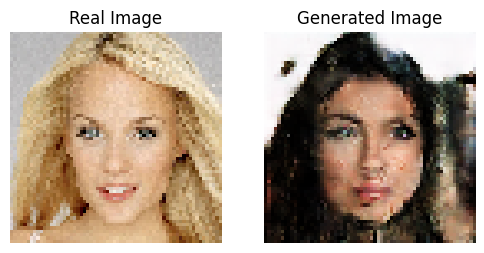

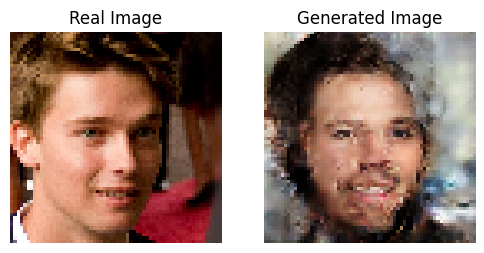

[Epoch 25/50] [Batch 0/468] [D loss: 0.0942] [G loss: 6.7438]


KeyboardInterrupt: 

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import torchvision.utils as vutils

adversarial_loss = nn.BCELoss()
conditional_loss = nn.CrossEntropyLoss()

# Define the hyperparameters
latent_dim = 100
num_epochs = 50
lr = 0.0002
load = True

# Initialize the generator and discriminator
generator = Generator(text_embedding_size=768, noise_dim=latent_dim).to(device)

discriminator = Discriminator().to(device)

# Define the optimizers
optimizer_G = optim.Adam(generator.parameters(), lr=lr, betas=(0.5, 0.999))
optimizer_D = optim.Adam(discriminator.parameters(), lr=lr, betas=(0.5, 0.999))

# Load the checkpoint
if load:
    checkpoint = torch.load('/content/drive/MyDrive/EmNoSNandNewEmbed/Final_50.pth')
    # Load the generator and discriminator state dicts
    generator.load_state_dict(checkpoint['generator'])
    discriminator.load_state_dict(checkpoint['discriminator'])
    # Load the optimizer state dicts
    optimizer_G.load_state_dict(checkpoint['gen_optimizer'])
    optimizer_D.load_state_dict(checkpoint['disc_optimizer'])
    print("Model load successfully>>>")

def plot_images(epoch, real_img, fake_img):

    real_img = (real_img + 1) / 2
    fake_img = (fake_img + 1) / 2

    plt.figure(figsize=(6, 3))
    plt.subplot(1, 2, 1)
    plt.title("Real Image")
    plt.imshow(real_img.permute(1, 2, 0).cpu().numpy())
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.title("Generated Image")
    plt.imshow(fake_img[0].permute(1, 2, 0).cpu().detach().numpy())
    plt.axis('off')

    # plt.savefig(f'epoch_{epoch}.png')
    plt.show()
# Start the training loop
jimg,jlab = dataset[8]
Rimg,Rlab = dataset[0]

# Start the training loop
for epoch in range(25,num_epochs):
    # Plot and save the first example and the generated image
    first_real_image = Rimg.to(device)
    first_condition = Rlab.unsqueeze(0).to(device)
    first_noise = torch.randn(1, latent_dim).to(device)
    first_fake_image = generator(first_noise, first_condition)
    plot_images(epoch, first_real_image, first_fake_image)
    # break
    first_real_image2 = jimg.to(device)
    first_condition2 = jlab.unsqueeze(0).to(device)
    first_noise2 = torch.randn(1, latent_dim).to(device)
    first_fake_image2 = generator(first_noise2, first_condition2)
    plot_images(epoch, first_real_image2, first_fake_image2)

    check_point = {
      'gen_optimizer':optimizer_G.state_dict(),
      'disc_optimizer':optimizer_D.state_dict(),
      'generator':generator.state_dict(),
      'discriminator':discriminator.state_dict()
    }
    torch.save(check_point, f'/content/Final_{epoch}.pth')
    for i, (real_images, conditions) in enumerate(trian_data_loader):
        batch_size = real_images.size(0)

        # Adversarial ground truths
        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)

        # Train the discriminator
        optimizer_D.zero_grad()
        conditions = conditions.to(device)
        real_images = real_images.to(device)
        # Generate fake samples
        noise = torch.randn(batch_size, latent_dim).to(device)
        fake_images = generator(noise, conditions).detach()

        # Compute discriminator loss on real samples
        real_outputs = discriminator(real_images, conditions)

        d_real_loss = adversarial_loss(real_outputs, real_labels)

        # Compute discriminator loss on fake samples
        fake_outputs = discriminator(fake_images, conditions)
        d_fake_loss = adversarial_loss(fake_outputs, fake_labels)

        # Total discriminator loss
        d_loss = d_real_loss + d_fake_loss
        d_loss.backward()
        optimizer_D.step()

        # Train the generator
        optimizer_G.zero_grad()

        # Generate fake samples
        noise = torch.randn(batch_size, latent_dim).to(device)
        fake_images = generator(noise, conditions)

        # Compute generator loss
        outputs = discriminator(fake_images, conditions)
        g_loss = adversarial_loss(outputs, real_labels)
        g_loss.backward()
        optimizer_G.step()

        # Print training stats
        if i % 500 == 0:
            print(f"[Epoch {epoch}/{num_epochs}] [Batch {i}/{len(trian_data_loader)}] [D loss: {d_loss.item():.4f}] [G loss: {g_loss.item():.4f}]")



# Save Model

In [ ]:
check_point = {
  'gen_optimizer':optimizer_G.state_dict(),
  'disc_optimizer':optimizer_D.state_dict(),
  'generator':generator.state_dict(),
  'discriminator':discriminator.state_dict()
}
torch.save(check_point, '/content/drive/MyDrive/EmNoSNandNewEmbed/Final_50.pth')

# Test Model

In [12]:
# prompt: generate code to  convert text in text.csv to its embedding using bert-base-uncased and to save it as its order in the np file

!pip install transformers

import torch
from transformers import BertTokenizer, BertModel
import numpy as np
import pandas as pd

# Load pre-trained BERT model and tokenizer
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
model = BertModel.from_pretrained('bert-base-uncased')

# Load the CSV file



/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

In [16]:
generator = Generator(text_embedding_size=768, noise_dim=100).to(device)
checkpoint = torch.load('/content/drive/MyDrive/MyEmNoSNandNewEmbed/Final_57.pth')
# Load the generator and discriminator state dicts
generator.load_state_dict(checkpoint['generator'])

<All keys matched successfully>

torch.Size([1, 768])


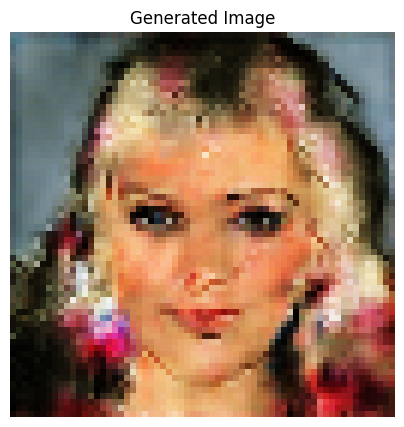

In [42]:
# prompt: generate code the take text and convert it to vec using the sent2vec function above and thin convert it to tensor to device

generator = Generator(text_embedding_size=768, noise_dim=100).to(device)
checkpoint = torch.load('/content/drive/MyDrive/MyEmNoSNandNewEmbed/Final_91.pth')
# Load the generator and discriminator state dicts
generator.load_state_dict(checkpoint['generator'])

text = "The person in the picture is attractive, young, smiling. This woman has arched eyebrows, blond hair, mouth slightly open, wavy hair. The person wears lipstick, heavy makeup."

encoded_input = tokenizer(text, return_tensors='pt', truncation=True, padding=True)
with torch.no_grad():
  model_output = model(**encoded_input)
embedding0 = model_output.pooler_output.numpy()
embedding0

vec = torch.tensor(embedding0).to(device)

print(vec.shape)

def plot_images(epoch, real_img, fake_img):

    real_img = (real_img + 1) / 2
    fake_img = (fake_img + 1) / 2

    plt.figure(figsize=(5, 5))
    plt.title("Generated Image")
    plt.imshow(fake_img[0].permute(1, 2, 0).cpu().detach().numpy())
    plt.axis('off')

    # plt.savefig(f'epoch_{epoch}.png')
    plt.show()

noise = torch.randn(1, 100).to(device)
fake_image = generator(noise, vec)
plot_images(0, fake_image, fake_image)


torch.Size([1, 768])


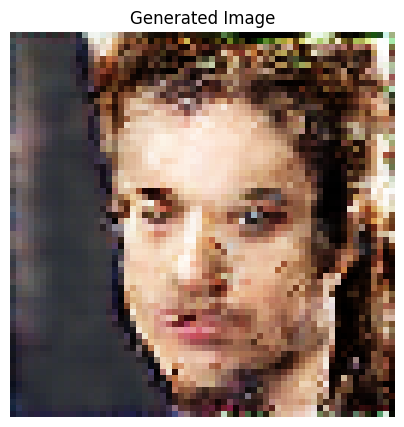

In [53]:
# prompt: generate code the take text and convert it to vec using the sent2vec function above and thin convert it to tensor to device

generator = Generator(text_embedding_size=768, noise_dim=100).to(device)
checkpoint = torch.load('/content/drive/MyDrive/MyEmNoSNandNewEmbed/Final_92.pth')
# Load the generator and discriminator state dicts
generator.load_state_dict(checkpoint['generator'])

text = "The person in the picture is young. This man is with bags under eyes, brown hair, pointy nose, mouth slightly open. The person wears ."

encoded_input = tokenizer(text, return_tensors='pt', truncation=True, padding=True)
with torch.no_grad():
  model_output = model(**encoded_input)
embedding0 = model_output.pooler_output.numpy()
embedding0

vec = torch.tensor(embedding0).to(device)

print(vec.shape)

def plot_images(epoch, real_img, fake_img):

    real_img = (real_img + 1) / 2
    fake_img = (fake_img + 1) / 2

    plt.figure(figsize=(5, 5))
    plt.title("Generated Image")
    plt.imshow(fake_img[0].permute(1, 2, 0).cpu().detach().numpy())
    plt.axis('off')
    plt.show()

noise = torch.randn(1, 100).to(device)
fake_image = generator(noise, vec)
plot_images(0, fake_image, fake_image)


torch.Size([1, 768])


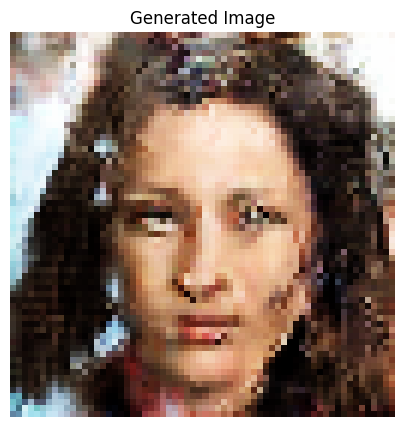

In [38]:
# prompt: generate code the take text and convert it to vec using the sent2vec function above and thin convert it to tensor to device

generator = Generator(text_embedding_size=768, noise_dim=100).to(device)
checkpoint = torch.load('/content/drive/MyDrive/MyEmNoSNandNewEmbed/Final_92.pth')
# Load the generator and discriminator state dicts
generator.load_state_dict(checkpoint['generator'])

text = "The person in the picture is attractive, young. She has arched eyebrows, big lips, brown hair, pointy nose, wavy hair. The woman wears lipstick."

encoded_input = tokenizer(text, return_tensors='pt', truncation=True, padding=True)
with torch.no_grad():
  model_output = model(**encoded_input)
embedding0 = model_output.pooler_output.numpy()
embedding0

vec = torch.tensor(embedding0).to(device)

print(vec.shape)

def plot_images(epoch, real_img, fake_img):

    real_img = (real_img + 1) / 2
    fake_img = (fake_img + 1) / 2

    plt.figure(figsize=(5, 5))
    plt.title("Generated Image")
    plt.imshow(fake_img[0].permute(1, 2, 0).cpu().detach().numpy())
    plt.axis('off')

    # plt.savefig(f'epoch_{epoch}.png')
    plt.show()

noise = torch.randn(1, 100).to(device)
fake_image = generator(noise, vec)
plot_images(0, fake_image, fake_image)


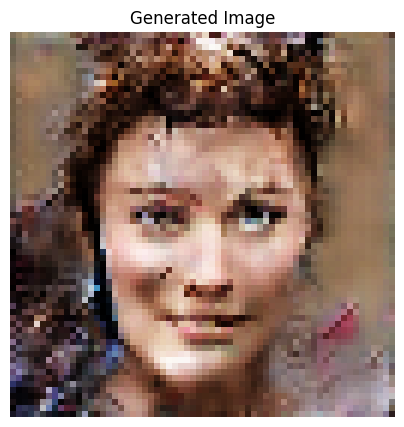

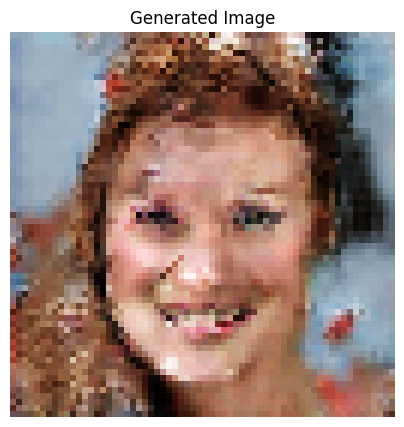

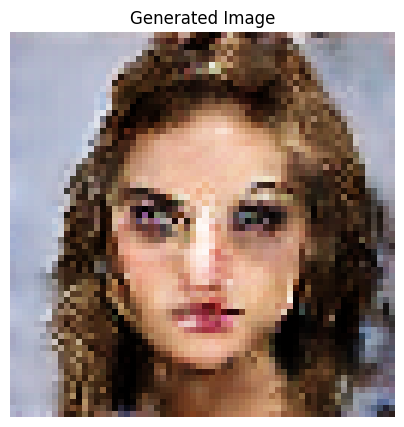

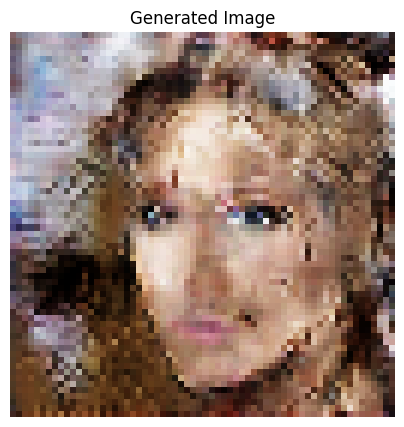

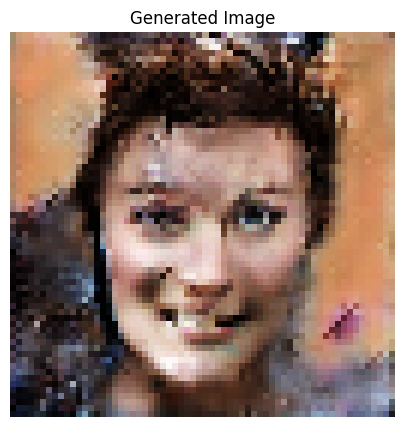

In [49]:
# prompt: generate code the take text and convert it to vec using the sent2vec function above and thin convert it to tensor to device

generator = Generator(text_embedding_size=768, noise_dim=100).to(device)
checkpoint = torch.load('/content/drive/MyDrive/MyEmNoSNandNewEmbed/Final_95.pth')
# Load the generator and discriminator state dicts
generator.load_state_dict(checkpoint['generator'])

text = "The person in the picture is attractive, young. She has arched eyebrows, big lips, brown hair, pointy nose, wavy hair. The woman wears lipstick."

encoded_input = tokenizer(text, return_tensors='pt', truncation=True, padding=True)
with torch.no_grad():
  model_output = model(**encoded_input)
embedding0 = model_output.pooler_output.numpy()
embedding0

vec = torch.tensor(embedding0).to(device)



def plot_images(epoch, real_img, fake_img):

    real_img = (real_img + 1) / 2
    fake_img = (fake_img + 1) / 2

    plt.figure(figsize=(5, 5))
    plt.title("Generated Image")
    plt.imshow(fake_img[0].permute(1, 2, 0).cpu().detach().numpy())
    plt.axis('off')
    plt.show()

for i in range(5):
    noise = torch.randn(1, 100).to(device)
    fake_image = generator(noise, vec)
    plot_images(0, fake_image, fake_image)
